In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [3]:
df =  pd.read_csv(r"C:\Users\vivek yadav\Downloads\insurance.csv")

In [4]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# EDA steps of eda

In [ ]:
df.shape

In [ ]:
df.head() # first 5 element want not full data

In [ ]:
df.info() # information 

In [ ]:
df.describe() # if you want to find out the mean mode or things you can so this 

In [ ]:
df.isnull().sum() # want to find any  null 

In [ ]:
df.columns # now i have to make the distrubution plot

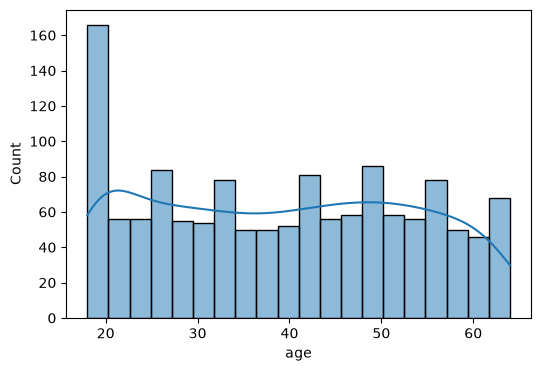

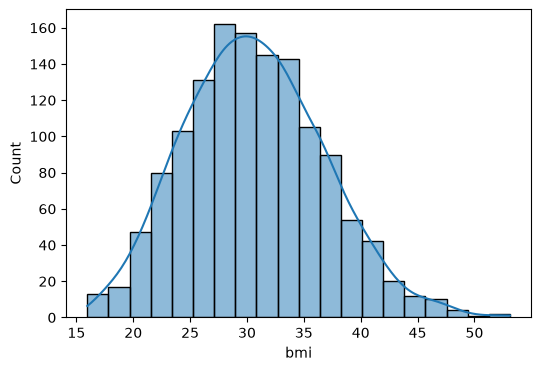

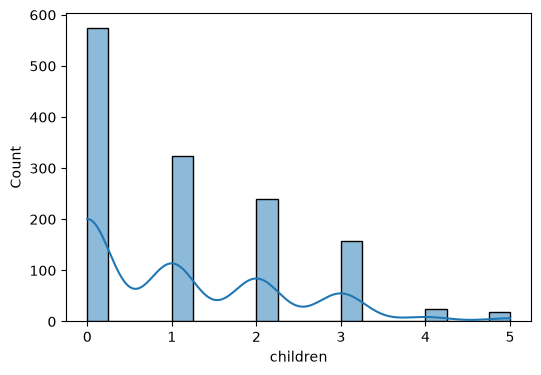

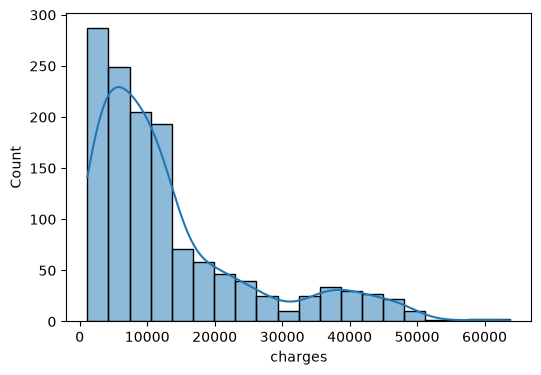

In [5]:

numeric_columns = ['age', 'bmi', 'children', 'charges']

for col in numeric_columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True, bins=20)
    


# now i have to use the string column to make the countplot

<Axes: xlabel='children', ylabel='count'>

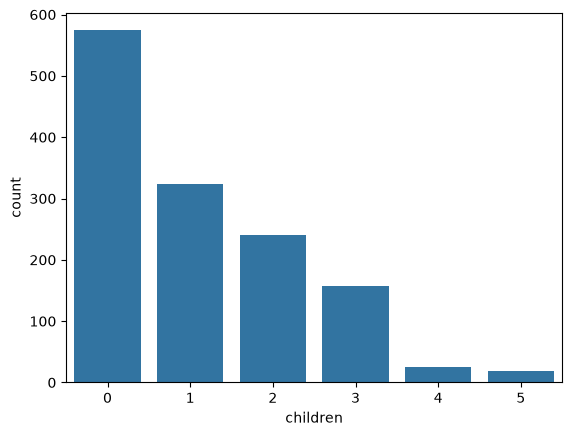

In [6]:
sns.countplot(x = df['children'])

<Axes: xlabel='sex', ylabel='count'>

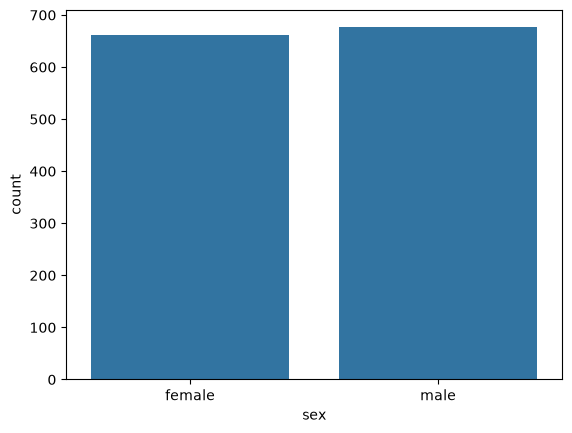

In [7]:
sns.countplot(x= df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

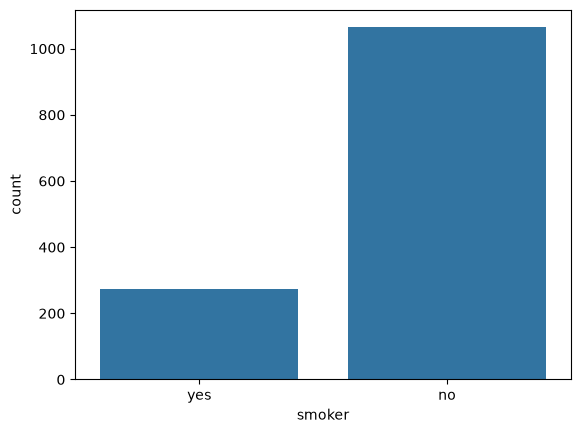

In [8]:
sns.countplot(x= df['smoker'])

# now i to make box plot

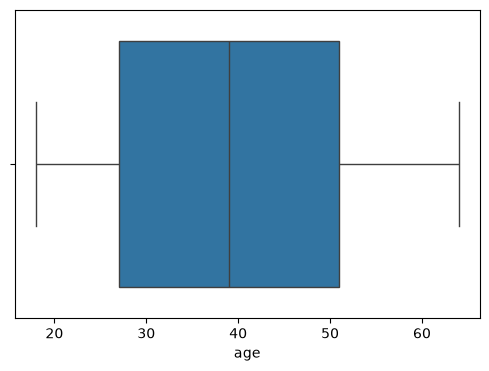

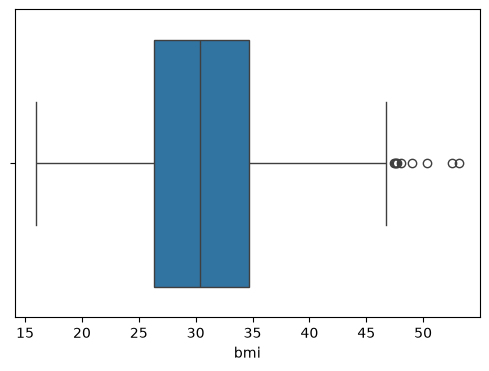

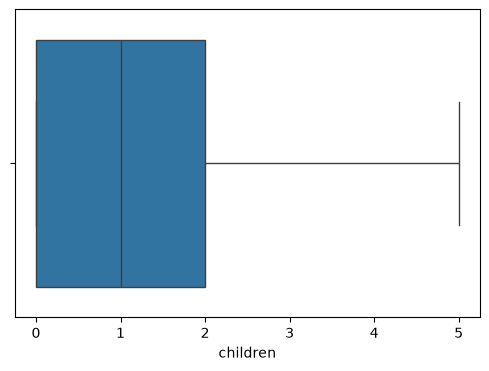

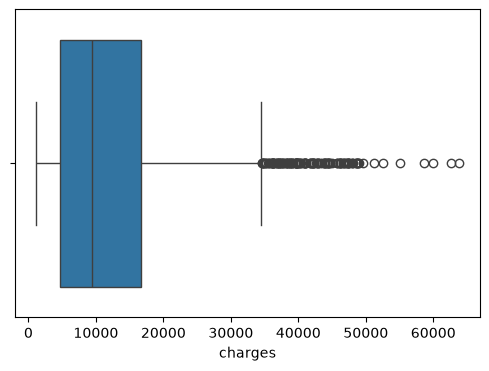

In [9]:
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x= df[col])

# the small box is showing it is showing this is outliers bro 

# nwo i have to make the correlation so we use heatmap

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

# data cleaning and processing

#for data cleaning you have to remove the null value and remove the outliers bro but there is no null value now i have to make another variable bro means like i have to save a fit bro the perfect cleaned data save

In [10]:
df_cleaned = df.copy()

In [11]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [12]:
df_cleaned.shape

(1338, 7)

In [13]:
df_cleaned.drop_duplicates(inplace = True)

In [14]:
df_cleaned.shape

(1337, 7)

In [15]:
df_cleaned.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

# if you want to make the model in machine learning then you have to convert the numeric

In [ ]:
df_cleaned['sex'].value_counts() # why we do ths like a lot of word is wite like male and Male so these are not same and i hvae  to the things for this is we are you using value counts

# now i have to conver the integer this is called level encoding


In [16]:
df_cleaned['sex'] = df_cleaned['sex'].map({"male" : 0,"female" : 1}) 

In [17]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [18]:
df_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [19]:
df_cleaned['smoker'] = df_cleaned['smoker'].map({"no" : 0,"yes" : 1}) 

In [20]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [21]:
df_cleaned.rename(columns={
    'sex':'is_female',
    'smoker': 'is_smoker'
}, inplace = True)

In [22]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [23]:
df_cleaned['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [ ]:
# we can do the same with dictionary but lets do something like one hot encoding: new column create

In [27]:
df_cleaned= pd.get_dummies(df_cleaned, columns = ['region'],drop_first=True)

In [28]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,True
1,18,0,33.770,1,0,1725.55230,False,True,False
2,28,0,33.000,3,0,4449.46200,False,True,False
3,33,0,22.705,0,0,21984.47061,True,False,False
4,32,0,28.880,0,0,3866.85520,True,False,False


In [ ]:
df_cleaned = df_cleaned.astype(int)

In [ ]:
df_cleaned.head()

# feature engineering and extraction

#now we add a new column on the basis of research bro this is engineering nwo from there we are making mdoel bro you have to research bro then you have to add the new column

In [29]:
df_cleaned['bmi_category'] = pd.cut(
    df_cleaned['bmi'],
    bins = [0,18.5,24.9,29.9, float('inf')],
    labels= ['underweight','Normal','overweight','Obese']
    
) # here we make another column for rhe bmi bro where bins is value and labes is vlaue that i have to put bro 

In [30]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27.900,0,1,16884.92400,False,False,True,overweight
1,18,0,33.770,1,0,1725.55230,False,True,False,Obese
2,28,0,33.000,3,0,4449.46200,False,True,False,Obese
3,33,0,22.705,0,0,21984.47061,True,False,False,Normal
4,32,0,28.880,0,0,3866.85520,True,False,False,overweight


In [31]:
df_cleaned= pd.get_dummies(df_cleaned, columns = ['bmi_category'],drop_first=True)

In [32]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_overweight,bmi_category_Obese
0,19,1,27.900,0,1,16884.92400,False,False,True,False,True,False
1,18,0,33.770,1,0,1725.55230,False,True,False,False,False,True
2,28,0,33.000,3,0,4449.46200,False,True,False,False,False,True
3,33,0,22.705,0,0,21984.47061,True,False,False,True,False,False
4,32,0,28.880,0,0,3866.85520,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,True,False,False,False,False,True
1334,18,1,31.920,0,0,2205.98080,False,False,False,False,False,True
1335,18,1,36.850,0,0,1629.83350,False,True,False,False,False,True
1336,21,1,25.800,0,0,2007.94500,False,False,True,False,True,False


In [33]:
df_cleaned = df_cleaned.astype(int)

In [34]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,1,0,1,0
1,18,0,33,1,0,1725,0,1,0,0,0,1
2,28,0,33,3,0,4449,0,1,0,0,0,1
3,33,0,22,0,0,21984,1,0,0,1,0,0
4,32,0,28,0,0,3866,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0,0,0,1
1334,18,1,31,0,0,2205,0,0,0,0,0,1
1335,18,1,36,0,0,1629,0,1,0,0,0,1
1336,21,1,25,0,0,2007,0,0,1,0,1,0


In [35]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_Normal', 'bmi_category_overweight', 'bmi_category_Obese'],
      dtype='str')

In [39]:
from sklearn.preprocessing import StandardScaler
cols_to_scale = ['age', 'bmi', 'children']
scaler = StandardScaler()
df_cleaned[cols_to_scale] = scaler.fit_transform(df_cleaned[cols_to_scale])

In [40]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,1,0,0,0,1,0


In [43]:

from scipy.stats import pearsonr
import pandas as pd

# Features to compare with insurance charges
selected_features = [
    'age', 'bmi', 'children', 'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal',
    'bmi_category_overweight',
    'bmi_category_Obese'
]

# Check that every selected feature exists
missing = [col for col in selected_features + ['charges']
           if col not in df_cleaned.columns]

if missing:
    print("Missing columns:", missing)
else:
    correlations = {
        feature: pearsonr(
            df_cleaned[feature],
            df_cleaned['charges']
        )[0]
        for feature in selected_features
    }

    correlation_df = pd.DataFrame(
        correlations.items(),
        columns=['Feature', 'Pearson Correlation']
    )

    display(
        correlation_df.sort_values(
            by='Pearson Correlation',
            ascending=False
        )
    )


,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298309
10,bmi_category_Obese,0.197660
1,bmi,0.196236
6,region_southeast,0.073577
2,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,is_female,-0.058046
8,bmi_category_Normal,-0.105656


In [44]:
cat_features = [
    'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
]

In [46]:
print(df_cleaned.columns.tolist())
print(cat_features)

['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_Normal', 'bmi_category_overweight', 'bmi_category_Obese', 'charges_bin']
['is_female', 'is_smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese']


In [47]:
cat_features = [
    'is_smoker',
    'is_female',
    'region_northwest',
    'region_southeast',
    'region_southwest',
    'bmi_category_Normal',
    'bmi_category_overweight',
    'bmi_category_Obese'
]

In [48]:

from scipy.stats import chi2_contingency
import pandas as pd

alpha = 0.05

# Bin insurance charges into four groups
df_cleaned['charges_bin'] = pd.qcut(
    df_cleaned['charges'],
    q=4,
    labels=False,
    duplicates='drop'
)

# Verify all feature names before testing
missing = [col for col in cat_features
           if col not in df_cleaned.columns]

if missing:
    print("These columns are missing:", missing)
else:
    chi2_results = {}

    for col in cat_features:
        contingency = pd.crosstab(
            df_cleaned[col],
            df_cleaned['charges_bin']
        )

        chi2_stat, p_val, _, _ = chi2_contingency(contingency)

        decision = (
            'Reject Null (Keep Feature)'
            if p_val < alpha
            else 'Fail to Reject Null'
        )

        chi2_results[col] = {
            'chi2_statistic': chi2_stat,
            'p_value': p_val,
            'Decision': decision
        }

    chi2_df = pd.DataFrame(chi2_results).T
    chi2_df = chi2_df.sort_values(by='p_value')
    display(chi2_df)


,chi2_statistic,p_value,Decision
is_smoker,848.219178,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
is_female,10.258784,0.01649,Reject Null (Keep Feature)
bmi_category_Obese,7.654464,0.05372,Fail to Reject Null
region_southwest,5.091893,0.165191,Fail to Reject Null
bmi_category_Normal,4.263673,0.234364,Fail to Reject Null
bmi_category_overweight,4.201575,0.240504,Fail to Reject Null
region_northwest,1.13424,0.768815,Fail to Reject Null


In [49]:
final_df = df_cleaned[['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges','region_southeast','bmi_category_Obese','region_northwest']]


In [50]:
final_df

,age,is_female,bmi,children,is_smoker,charges,region_southeast,bmi_category_Obese,region_northwest
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0
1,-1.511647,0,0.462463,-0.079442,0,1725,1,1,0
2,-0.799350,0,0.462463,1.580143,0,4449,1,1,0
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,0,1
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,0,1
...,...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1,1
1334,-1.511647,1,0.135659,-0.909234,0,2205,0,1,0
1335,-1.511647,1,0.952670,-0.909234,0,1629,1,1,0
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,0,0


In [51]:
from sklearn.model_selection import train_test_split

In [52]:
X = final_df.drop('charges', axis=1)
y = final_df['charges']

In [53]:
 X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [54]:
from sklearn.linear_model import LinearRegression

In [55]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[3557.98, 70.24, 634.91,...,-402.44,3196.08, -11.06]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['age','is_female','bmi',...,'region_southeast','bmi_category_Obese', 'region_northwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6755
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [56]:
y_pred = model.predict(X_test)

In [57]:
y_pred 

array([ 7.92366324e+03,  4.92258266e+03,  1.44028222e+04,  3.18161761e+04,
        8.65847190e+03,  1.31165421e+04,  2.96559633e+04,  1.35867541e+03,
        1.10371607e+04,  9.79967079e+03,  1.09203172e+04,  3.19514094e+04,
        3.11338597e+04,  1.65135902e+04,  1.01448909e+04,  8.37545937e+03,
        5.33287616e+03,  3.19526496e+04,  3.04148336e+03,  3.67053437e+03,
        4.57915300e+03,  2.84327942e+04,  1.37055133e+04,  2.91930968e+04,
        3.12324427e+04,  6.06702988e+03,  3.44837567e+04,  3.77047412e+04,
        1.24414769e+04,  1.39011161e+04,  7.56187599e+03,  1.29484457e+04,
        1.90041772e+02,  1.13982622e+04,  3.74081225e+04,  1.33633263e+04,
        3.12100717e+03,  4.12095860e+03,  3.10872453e+04,  7.87517040e+03,
        6.11093035e+03,  2.98686470e+04,  3.45697503e+04,  1.30855909e+04,
        7.75437505e+03,  2.98302584e+03,  5.20093884e+03,  7.62105046e+03,
        3.39350049e+03,  1.00634739e+04,  7.44968787e+03,  1.06603026e+04,
        2.99658426e+04,  

In [58]:
y_test

900      8688
1064     5708
1256    11436
298     38746
237      4463
        ...  
731     10065
321     24671
477      2534
784      4350
1193     8671
Name: charges, Length: 442, dtype: int64

In [59]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test,y_pred)
r2
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - ((1- r2) * (n-1) / (n - p - 1))
adjusted_r2

0.7682986741150772